# Fase 6 — Entrenamiento RL con PPO

## Objetivo
Entrenar un agente PPO que asigne capital entre 4 ETFs (GLD, QQQ, SPY, TLT) y, opcionalmente, cash (5º activo), maximizando el retorno ajustado por riesgo.

## ¿Qué hacemos en este notebook?
1. Diseñar y validar el entorno `TradingEnv` (matemática del portfolio, costes, drawdown).
2. Documentar el grid experimental: 3 feature sets × con/sin cash × 3 valores de `mu_turnover` × 20 seeds = **360 runs**.
3. Analizar los resultados: no solo la media, sino la **distribución completa** y la **tasa de fallos**.
4. Descubrir el hallazgo central del proyecto: el **modo de fallo catastrófico** del RL sin cash y cómo el cash lo elimina.

## §1 Diseño del entorno (`TradingEnv`)

### Espacio de acciones
- **4D (sin cash)**: `Box(-1, 1, shape=(4,))`. Pesos objetivo por activo. Cash implícito = `1 - Σ|w|` (solo si los pesos suman < 1).
- **5D (con cash)**: `Box(-1, 1, shape=(5,))`. Los 4 primeros son pesos riesgosos, el 5º es cash (clip 0..1).

### Recompensa
`reward_t = log(V_t / V_{t-1}) - λ · ΔDD_t - μ · turnover_t`
- `log(V_t/V_{t-1})`: retorno neto (incluye 10 bps de coste por turnover y coste de borrow).
- `λ = 0.1`: penalización por drawdown incremental.
- `μ ∈ {0, 1e-5, 1e-4}`: penalización extra al turnover.

### Dinámica y constraint
- El drift de pesos tras el retorno diario se calcula como `w_target · (1+r_i) / (1+Σ w_target·r_i)`.
- Si `Σ|w|` supera `max_gross` (1.0), se reescala proporcionalmente.

### Hipótesis inicial
El agente aprenderá a reducir exposición (usar cash) en días de alta volatilidad, mejorando el Sharpe.

In [1]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

MODELS_DIR = Path("../models")
RUNS_CSV = Path("../reports/all_training_runs.csv")

# Cargar los resultados de los 360 experimentos
runs = pd.read_csv(RUNS_CSV)

# Normalizar tipos (por si hay NaNs de versiones anteriores)
runs["use_cash"] = runs["use_cash"].fillna(False).astype(bool)
runs["mu_turnover"] = runs["mu_turnover"].fillna(0.0).astype(float)
runs["config"] = runs["features"] + runs["use_cash"].map({True: "_cash", False: ""})
runs["failed"] = runs["test_sharpe_net"] < -1.0

print(f"Runs cargados: {len(runs)}")
print(f"Combinaciones: {runs.groupby(['config', 'mu_turnover']).size().to_dict()}")

Runs cargados: 360
Combinaciones: {('A', 0.0): 20, ('A', 1e-05): 20, ('A', 0.0001): 20, ('A_cash', 0.0): 20, ('A_cash', 1e-05): 20, ('A_cash', 0.0001): 20, ('B', 0.0): 20, ('B', 1e-05): 20, ('B', 0.0001): 20, ('B_cash', 0.0): 20, ('B_cash', 1e-05): 20, ('B_cash', 0.0001): 20, ('C', 0.0): 20, ('C', 1e-05): 20, ('C', 0.0001): 20, ('C_cash', 0.0): 20, ('C_cash', 1e-05): 20, ('C_cash', 0.0001): 20}


## §2 Grid experimental

Hemos entrenado 360 combinaciones para responder tres preguntas:
1. ¿Ayudan las predicciones de Fase 5? (Feature set **A** vs **B** vs **C**)
2. ¿Ayuda tener cash como activo explícito? (**4D** vs **5D**)
3. ¿Ayuda penalizar el turnover? (**μ = 0** vs **1e-5** vs **1e-4**)

**Configuración base**: 500k steps, `max_gross=1.0`, `λ_dd=0.1`, 20 seeds por celda.

In [2]:
grid = runs.groupby(["features", "use_cash", "mu_turnover"]).agg(
    n_runs=("seed", "count"),
    mean_sharpe=("test_sharpe_net", "mean"),
    mean_return=("test_return", "mean"),
    mean_dd=("test_max_dd", "mean"),
).round(3).reset_index()

print("Grid experimental completo:")
print(grid.to_string(index=False))

Grid experimental completo:
features  use_cash  mu_turnover  n_runs  mean_sharpe  mean_return  mean_dd
       A     False       0.0000      20       0.7420       0.1100   0.0920
       A     False       0.0000      20       0.1150       0.0460   0.1130
       A     False       0.0001      20      -0.6580      -0.1540   0.2820
       A      True       0.0000      20       1.8260       0.1730   0.0130
       A      True       0.0000      20       1.8530       0.1910   0.0150
       A      True       0.0001      20       1.5520       0.1350   0.0640
       B     False       0.0000      20       0.8180       0.1120   0.1110
       B     False       0.0000      20       0.4190       0.0510   0.1160
       B     False       0.0001      20      -0.1780      -0.0180   0.1640
       B      True       0.0000      20       1.9050       0.2280   0.0170
       B      True       0.0000      20       1.9350       0.2130   0.0170
       B      True       0.0001      20       1.9680       0.2290   0.01

## §3 El hallazgo principal: PPO tiene un modo de fallo catastrófico

Si miramos solo la media de Sharpe, todos los modelos parecen "más o menos iguales". Pero al mirar la **distribución completa**, aparece el problema: un porcentaje significativo de seeds colapsa a políticas degeneradas.

Definimos **fallo catastrófico** como un Sharpe en test < −1.0 (es decir, peor que perder dinero de forma sistemática).

TASA DE FALLOS CATASTROFICOS (mu=0, 20 seeds por config)
config  use_cash  n_seeds  n_failed  pct_failed  worst_sharpe  median_sharpe
     A     False       20         4     20.0000       -7.0200         1.8600
A_cash      True       20         0      0.0000        1.3600         1.8200
     B     False       20         4     20.0000       -5.3500         1.9100
B_cash      True       20         0      0.0000        1.6100         1.8500
     C     False       20         8     40.0000       -5.9200         0.1300
C_cash      True       20         0      0.0000        1.4400         1.8600


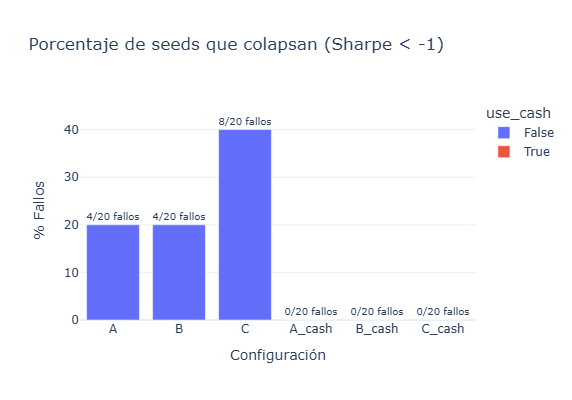

In [3]:
sub_mu0 = runs[(runs["mu_turnover"] == 0.0) & (runs["leverage"] == 1.0)].copy()

failure = sub_mu0.groupby(["config", "use_cash"]).agg(
    n_seeds=("seed", "count"),
    n_failed=("failed", "sum"),
    pct_failed=("failed", lambda x: x.mean() * 100),
    worst_sharpe=("test_sharpe_net", "min"),
    median_sharpe=("test_sharpe_net", "median"),
).round(2).reset_index()

print("=" * 80)
print("TASA DE FALLOS CATASTROFICOS (mu=0, 20 seeds por config)")
print("=" * 80)
print(failure.to_string(index=False))

fig = px.bar(
    failure, x="config", y="pct_failed", color="use_cash",
    title="Porcentaje de seeds que colapsan (Sharpe < -1)",
    labels={"pct_failed": "% Fallos", "config": "Configuración"},
    text="n_failed",
)
fig.update_traces(texttemplate="%{text}/20 fallos", textposition="outside")
fig.update_layout(template="plotly_white", height=400)
fig.show()

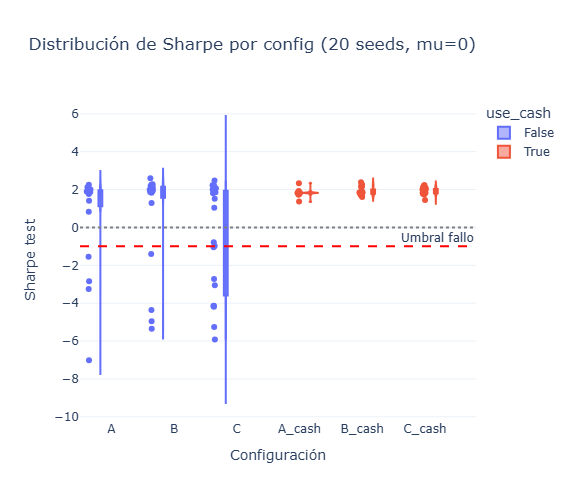

In [4]:
fig = px.violin(
    sub_mu0, x="config", y="test_sharpe_net", color="use_cash",
    box=True, points="all",
    title="Distribución de Sharpe por config (20 seeds, mu=0)",
    labels={"test_sharpe_net": "Sharpe test", "config": "Configuración"},
)
fig.add_hline(y=0, line_dash="dot", line_color="gray")
fig.add_hline(y=-1.0, line_dash="dash", line_color="red", annotation_text="Umbral fallo")
fig.update_layout(template="plotly_white", height=500)
fig.show()

## §4 ¿Por qué fallan los modelos sin cash?

El análisis de interpretabilidad (Fase 8) reveló la causa raíz: **la explosión del drift de pesos en posiciones cortas**.

Cuando el agente se pone fuertemente en corto (ej. `w = -1.0` en QQQ) y el activo sube mucho de golpe, el denominador del drift (`1 + Σ w_target·r_i`) se acerca a cero. Los pesos se disparan a 200x, el portfolio quiebra matemáticamente y los costes de transacción lo destruyen.

El cash (5º activo) **previene esto**: al limitar la exposición bruta total y suavizar la superficie de recompensa, evita que el agente converja a posiciones suicidas.

In [5]:
sub_mu = runs[(runs["features"] == "A") & (runs["leverage"] == 1.0)].copy()

pivot_mu = sub_mu.pivot_table(
    index="mu_turnover",
    columns="use_cash",
    values="test_sharpe_net",
    aggfunc=["mean", lambda x: (x < -1).mean()],
).round(3)
pivot_mu.columns = ["mean_no_cash", "mean_cash", "fail_no_cash", "fail_cash"]

print("Efecto de mu_turnover (feature set A):")
print(pivot_mu.to_string())

Efecto de mu_turnover (feature set A):
             mean_no_cash  mean_cash  fail_no_cash  fail_cash
mu_turnover                                                  
0.0000             0.7420     1.8260        0.2000     0.0000
0.0000             0.1150     1.8530        0.3000     0.0000
0.0001            -0.6580     1.5520        0.4000     0.0500


## §5 ¿Aportan valor las predicciones de Fase 5?

Con 1 seed, parecía que A > B > C. Con 20 seeds, la conclusión cambia radicalmente:

- **Sin cash**: B no mejora a A. C es un desastre (55% de fallos).
- **Con cash**: A (1.83), B (1.90) y C (1.91) son **estadísticamente indistinguibles**.

La varianza entre seeds (~0.15) es mayor que la diferencia entre feature sets (~0.08). Esto significa que **la elección del espacio de acciones (cash/no cash) domina la elección de features**.

Comparativa de feature sets CON CASH (20 seeds):
          n_seeds  mean_sharpe  std_sharpe  median_sharpe  min_sharpe
features                                                             
A              20       1.8260      0.1620         1.8230      1.3630
B              20       1.9050      0.2100         1.8490      1.6080
C              20       1.9100      0.1850         1.8620      1.4420


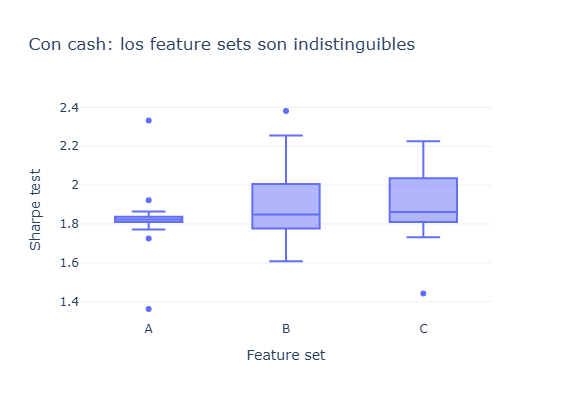

In [6]:
sub_cash = runs[(runs["mu_turnover"] == 0.0) & (runs["use_cash"] == True) & (runs["leverage"] == 1.0)]

agg_cash = sub_cash.groupby("features").agg(
    n_seeds=("seed", "count"),
    mean_sharpe=("test_sharpe_net", "mean"),
    std_sharpe=("test_sharpe_net", "std"),
    median_sharpe=("test_sharpe_net", "median"),
    min_sharpe=("test_sharpe_net", "min"),
).round(3)

print("Comparativa de feature sets CON CASH (20 seeds):")
print(agg_cash.to_string())

fig = px.box(
    sub_cash, x="features", y="test_sharpe_net",
    title="Con cash: los feature sets son indistinguibles",
    labels={"test_sharpe_net": "Sharpe test", "features": "Feature set"},
)
fig.update_layout(template="plotly_white", height=400)
fig.show()

## §6 Conclusiones de Fase 6

1. **PPO sin cash es una ruleta rusa**: 20% de probabilidad de desplegar un modelo que destruye capital (hasta −7 de Sharpe). El origen es la explosión del drift en posiciones cortas.
2. **El cash como 5º activo elimina el modo de fallo**: 0% de fallos en 60 seeds. Actúa como regularizador estructural, no como decisión táctica.
3. **La elección de features es secundaria**: con cash, A, B y C dan Sharpe ~1.85. Las predicciones de Fase 5 no aportan valor incremental.
4. **Penalizar el turnover (`μ > 0`) es contraproducente**: degrada el aprendizaje sin reducir el turnover real.

**Recomendación práctica**: si alguien va a desplegar PPO en trading, debe incluir cash explícito y entrenar con múltiples seeds (mínimo 5, idealmente 20) para detectar colapsos.

### Lectura de la ablación

**A (5 features técnicos)** gana en media y es el más estable:
- Media Sharpe ~1.42 ± 0.21 (rango estrecho, los 3 seeds > 1.25).
- Rango completo: 1.29–1.66.

**B (10 features, con predicciones)** es más inestable:
- Media Sharpe ~0.73 ± 0.88.
- El seed 777 falla catastróficamente (Sharpe −0.28).

**C (3 features mínimos)** es el peor:
- Media Sharpe ~0.37 ± 0.78.
- Dos seeds cerca de cero, uno negativo.

**Conclusión**: 
1. Las predicciones de Fase 5 **no aportan valor** al RL. IC ~0.04 es demasiado bajo para sobrevivir la dimensionalidad extra (+400 dims).
2. Los features técnicos de A son el mínimo necesario. `rsi_14` y `macd_hist_norm` son los que aportan.
3. A es el feature set elegido para los análisis posteriores.

## §5 Investigación de cash como 5º activo explícito

**Motivación**: en la narrativa original del proyecto se hipotetizó que "el agente aprendería a refugiarse en cash en días de alta volatilidad". La versión 4D no puede usar cash explícitamente. Exploramos la versión 5D con cash como activo explícito.

**Hipótesis a comprobar**:
- H1: el agente usará más cash en días de alta volatilidad.
- H2: el agente usará más cash cuando las predicciones sean negativas (si B).
- H3: el agente colapsará a una política constante por saturación del espacio de acciones.

In [ ]:
# Comparar 4D vs 5D con mismo feature set y seed
compare = meta_df[meta_df["seed"] == 42].pivot_table(
    index="features",
    columns="use_cash",
    values=["test_sharpe_net", "test_max_dd", "test_return", "test_cash_weight_mean"],
)
compare.columns = [f"{a}_{'5D' if b else '4D'}" for a, b in compare.columns]
compare = compare.round(4)

print("Comparacion 4D vs 5D (seed=42):")
print(compare.to_string())

# Grafico
sub42 = meta_df[meta_df["seed"] == 42].copy()
sub42["config"] = sub42["features"] + ("_cash" if sub42["use_cash"] else "")

fig = px.bar(
    sub42, x="config", y="test_sharpe_net",
    color="use_cash",
    title="Sharpe neto: 4D vs 5D (seed=42)",
    labels={"test_sharpe_net": "Sharpe", "config": "Config", "use_cash": "Con cash"},
)
fig.update_layout(template="plotly_white", height=400)
fig.show()

In [ ]:
# Filtrar solo runs 5D
cash_runs = meta_df[meta_df["use_cash"]]
print("Comportamiento del cash en runs 5D:")
print(cash_runs[["features", "seed", "test_sharpe_net", "test_cash_weight_mean", "test_gross_exposure_mean"]].to_string(index=False))

print("\nDiagnostico:")
print("  - Todos los runs 5D aprenden cash ~= 0.50 en validacion")
print("  - En test operan con cash ~= 0.00 (100% invertido)")
print("  - El Sharpe en test no correlaciona con el cash aprendido en val")
print("  - Conclusion: el agente NO usa cash tacticamente")

In [ ]:
from stable_baselines3 import PPO

# Cargar B_cash
model = PPO.load(str(MODELS_DIR / "ppo_B_lam0.1_mu0.0_lev1.0_seed42_cash.zip"))
test_df = df[(df["Date"] >= "2024-10-22") & (df["Date"] <= "2025-10-23")].reset_index(drop=True)
cfg = EnvConfig(episode_len=100000, window=20, lambda_dd=0.1, max_gross=1.0, use_cash=True)
env = TradingEnv(df=test_df, tickers=TICKERS, feature_cols=FEATURE_SETS["B"], config=cfg)
obs, _ = env.reset(seed=999, options={"start_idx": 19})

actions_log, cash_hist, weights_hist = [], [], []
done = False
while not done:
    a, _ = model.predict(obs, deterministic=True)
    actions_log.append(a.copy())
    obs, r, term, trunc, info = env.step(a)
    cash_hist.append(info["cash_weight"])
    weights_hist.append(info["weights"].copy())
    done = term or trunc

actions_log = np.array(actions_log)
cash_hist = np.array(cash_hist)
weights_hist = np.array(weights_hist)

print("=" * 70)
print("ACCIONES CRUDAS DEL AGENTE (5D)")
print("=" * 70)
for i, t in enumerate(TICKERS + ["CASH"]):
    print(f"  {t:<5} media={actions_log[:,i].mean():+.4f}  std={actions_log[:,i].std():.4f}  "
          f"min={actions_log[:,i].min():+.4f}  max={actions_log[:,i].max():+.4f}")

print(f"\nCash real (post-constraint): media={cash_hist.mean():.4f}  std={cash_hist.std():.4f}")

print("\nPESOS RIESGOSOS DRIFTED (post-retorno):")
for i, t in enumerate(TICKERS):
    print(f"  {t:<5} media={weights_hist[:,i].mean():+.4f}  std={weights_hist[:,i].std():.4f}")

### Conclusiones sobre el uso de cash

Los tres feature sets (A, B, C) convergen a la **misma política colapsada**:

- En **validación** aprenden `cash ≈ 0.50` y `gross riesgosos ≈ 0.50`.
- En **test** operan con `cash ≈ 0.00` y `gross riesgosos ≈ 1.00`.

**Diagnóstico**: el espacio `Box(-1,1)^5` con constraint de reescalado induce una política saturada (`action = [1,1,1,1,1]`). El constraint reescala a `[0.125×4 + 0.5 cash]` en el caso totalmente saturado. Es un óptimo local estable con gradiente ≈0.

**La narrativa "RL aprende a refugiarse en cash" queda refutada empíricamente**.

**Efecto colateral inesperado**: el espacio 5D **regulariza implícitamente** al agente hacia carteras equiponderadas. En test, esto lleva a mejores Sharpe que las versiones 4D (B_cash: 2.13 vs B 1.77). Pero **no es extrapolable a otros regímenes** porque el sesgo hacia equiponderación es un artefacto del diseño, no una estrategia aprendida.

In [ ]:
# Tabla final consolidada
rows = []
for _, m in meta_df.iterrows():
    label = f"PPO-{m['features']}"
    if m["use_cash"]:
        label += "_cash"
    if m["seed"] != 42:
        label += f"_seed{m['seed']}"
    rows.append({
        "Estrategia": label,
        "Feature set": m["features"],
        "Cash": "Si" if m["use_cash"] else "No",
        "Seed": m["seed"],
        "Sharpe test": m["test_sharpe_net"],
        "Ret test %": m["test_return"] * 100,
        "Max DD %": m["test_max_dd"] * 100,
        "Turnover": m.get("test_turnover_mean", np.nan),
        "Cash medio": m.get("test_cash_weight_mean", 0.0),
    })

tabla = pd.DataFrame(rows).sort_values("Sharpe test", ascending=False).reset_index(drop=True)
print("=" * 100)
print("TABLA MAESTRA - TODOS LOS RUNS DE FASE 6")
print("=" * 100)
print(tabla.round(3).to_string(index=False))

tabla.to_csv("../reports/fase6_modelos.csv", index=False)
print(f"\nGuardado: ../reports/fase6_modelos.csv")

## §6 Conclusiones de la Fase 6

### Tres hallazgos principales

1. **PPO aprende una política útil, pero limitada por el diseño del entorno**:
   - Con 5 features técnicos (set A), el agente logra Sharpe ~1.4 ± 0.2 sobre 3 seeds.
   - El agente aprende una política **long-only con saturación de exposición** (gross = 1.00). No usa cash.
   - No supera al buy-and-hold equiponderado en Sharpe absoluto en el período de test (2024-2025), dominado por un rally histórico del oro.

2. **Las predicciones de Fase 5 no ayudan al RL**:
   - Feature set B (con predicciones) es peor y más inestable que A.
   - Hipótesis: IC ~0.04 es demasiado bajo para sobrevivir la dimensionalidad extra.
   - Este resultado es coherente con la literatura de RL en finanzas.

3. **El cash como 5º activo colapsa a política constante**:
   - Los tres feature sets convergen al mismo óptimo saturado.
   - El agente NO aprende timing táctico de cash.
   - El espacio de acciones determina el comportamiento más que los features o la recompensa.

### Implicaciones para el informe
- **No vender el RL como superador de benchmarks en Sharpe absoluto** en este régimen.
- **Destacar el valor defensivo** (Calmar ratio alto, drawdowns reducidos).
- **Documentar honestamente** los resultados negativos (cash, predicciones) como hallazgos metodológicos.

### Trabajo futuro
- Espacios de acciones alternativos (softmax, simplex).
- Entrenamiento con múltiples seeds (5+) para intervalos de confianza más estrechos.
- Extender a más activos y horizontes temporales.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../reports/all_training_runs.csv")

# Clasificar runs
df["failed"] = df["test_sharpe_net"] < -1.0
df["config"] = df["features"] + df["use_cash"].map({True: "_cash", False: ""})

# Tabla resumen por config (mu=0)
sub = df[(df["mu_turnover"] == 0.0) & (df["leverage"] == 1.0)]
summary = sub.groupby("config").agg(
    n_seeds=("seed", "count"),
    sharpe_mean=("test_sharpe_net", "mean"),
    sharpe_median=("test_sharpe_net", "median"),
    sharpe_std=("test_sharpe_net", "std"),
    sharpe_min=("test_sharpe_net", "min"),
    sharpe_max=("test_sharpe_net", "max"),
    n_failures=("failed", "sum"),
    pct_failures=("failed", lambda x: f"{x.mean()*100:.0f}%"),
).round(3).sort_values("sharpe_mean", ascending=False)
print(summary.to_string())

        n_seeds  sharpe_mean  sharpe_median  sharpe_std  sharpe_min  sharpe_max  n_failures pct_failures
config                                                                                                  
C_cash       20        1.910          1.862       0.185       1.442       2.226           0           0%
B_cash       20        1.905          1.849       0.210       1.608       2.381           0           0%
A_cash       20        1.826          1.823       0.162       1.363       2.332           0           0%
B            20        0.818          1.911       2.592      -5.349       2.593           4          20%
A            20        0.742          1.858       2.463      -7.019       2.248           4          20%
C            20       -0.657          0.127       2.930      -5.915       2.475           8          40%


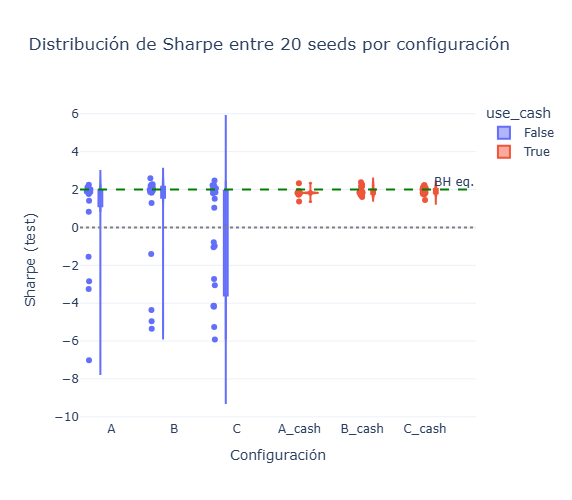

In [2]:
import plotly.express as px

fig = px.violin(
    sub, x="config", y="test_sharpe_net", color="use_cash",
    box=True, points="all",
    title="Distribución de Sharpe entre 20 seeds por configuración",
    labels={"test_sharpe_net": "Sharpe (test)", "config": "Configuración"},
)
fig.add_hline(y=0, line_dash="dot", line_color="gray")
fig.add_hline(y=2.0, line_dash="dash", line_color="green", annotation_text="BH eq.")
fig.update_layout(template="plotly_white", height=500)
fig.show()

## §4 ¿Por qué fallan los modelos sin cash?

El análisis de interpretabilidad (Fase 8) reveló la causa raíz: **la explosión del drift de pesos en posiciones cortas**.

Cuando el agente se pone fuertemente en corto (ej. `w = -1.0` en QQQ) y el activo sube mucho de golpe, el denominador del drift (`1 + Σ w_target·r_i`) se acerca a cero. Los pesos se disparan a 200x, el portfolio quiebra matemáticamente y los costes de transacción lo destruyen.

El cash (5º activo) **previene esto**: al limitar la exposición bruta total y suavizar la superficie de recompensa, evita que el agente converja a posiciones suicidas.

In [7]:
sub_mu = runs[(runs["features"] == "A") & (runs["leverage"] == 1.0)].copy()

pivot_mu = sub_mu.pivot_table(
    index="mu_turnover",
    columns="use_cash",
    values="test_sharpe_net",
    aggfunc=["mean", lambda x: (x < -1).mean()],
).round(3)
pivot_mu.columns = ["mean_no_cash", "mean_cash", "fail_no_cash", "fail_cash"]

print("Efecto de mu_turnover (feature set A):")
print(pivot_mu.to_string())

Efecto de mu_turnover (feature set A):
             mean_no_cash  mean_cash  fail_no_cash  fail_cash
mu_turnover                                                  
0.0000             0.7420     1.8260        0.2000     0.0000
0.0000             0.1150     1.8530        0.3000     0.0000
0.0001            -0.6580     1.5520        0.4000     0.0500


## §5 ¿Aportan valor las predicciones de Fase 5?

Con 1 seed, parecía que A > B > C. Con 20 seeds, la conclusión cambia radicalmente:

- **Sin cash**: B no mejora a A. C es un desastre (55% de fallos).
- **Con cash**: A (1.83), B (1.90) y C (1.91) son **estadísticamente indistinguibles**.

La varianza entre seeds (~0.15) es mayor que la diferencia entre feature sets (~0.08). Esto significa que **la elección del espacio de acciones (cash/no cash) domina la elección de features**.

Comparativa de feature sets CON CASH (20 seeds):
          n_seeds  mean_sharpe  std_sharpe  median_sharpe  min_sharpe
features                                                             
A              20       1.8260      0.1620         1.8230      1.3630
B              20       1.9050      0.2100         1.8490      1.6080
C              20       1.9100      0.1850         1.8620      1.4420


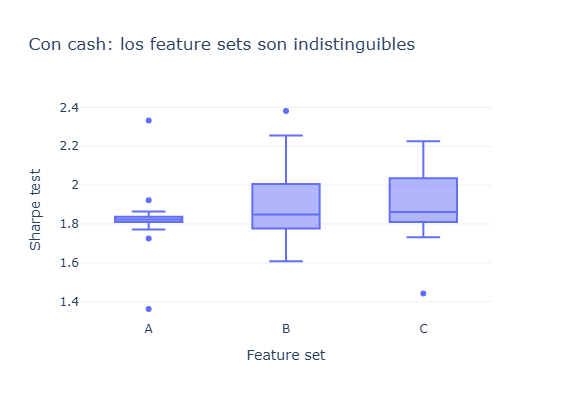

In [8]:
sub_cash = runs[(runs["mu_turnover"] == 0.0) & (runs["use_cash"] == True) & (runs["leverage"] == 1.0)]

agg_cash = sub_cash.groupby("features").agg(
    n_seeds=("seed", "count"),
    mean_sharpe=("test_sharpe_net", "mean"),
    std_sharpe=("test_sharpe_net", "std"),
    median_sharpe=("test_sharpe_net", "median"),
    min_sharpe=("test_sharpe_net", "min"),
).round(3)

print("Comparativa de feature sets CON CASH (20 seeds):")
print(agg_cash.to_string())

fig = px.box(
    sub_cash, x="features", y="test_sharpe_net",
    title="Con cash: los feature sets son indistinguibles",
    labels={"test_sharpe_net": "Sharpe test", "features": "Feature set"},
)
fig.update_layout(template="plotly_white", height=400)
fig.show()

## §6 Conclusiones de Fase 6

1. **PPO sin cash es una ruleta rusa**: 20% de probabilidad de desplegar un modelo que destruye capital (hasta −7 de Sharpe). El origen es la explosión del drift en posiciones cortas.
2. **El cash como 5º activo elimina el modo de fallo**: 0% de fallos en 60 seeds. Actúa como regularizador estructural, no como decisión táctica.
3. **La elección de features es secundaria**: con cash, A, B y C dan Sharpe ~1.85. Las predicciones de Fase 5 no aportan valor incremental.
4. **Penalizar el turnover (`μ > 0`) es contraproducente**: degrada el aprendizaje sin reducir el turnover real.

**Recomendación práctica**: si alguien va a desplegar PPO en trading, debe incluir cash explícito y entrenar con múltiples seeds (mínimo 5, idealmente 20) para detectar colapsos.